# Introduction to convolutional neural networks

Convolutional neural networks have proven to be very relevant for computer vision.
They are powerful tools to learn relevant features from some data types such as images.

The key elements of a convolutional neural network are the **convolutional layers** and the **pooling layers**.
In this short tutorial, we will illustrate these types of layers.

But first, we have to talk about **channels**.

> **Remark**: Some of the illustrations used in this tutorial come from this [GitHub repository](https://github.com/vdumoulin/conv_arithmetic/) and the [corresponding paper](https://arxiv.org/pdf/1603.07285.pdf).

## Channels

Even though 2D images are visually in two dimensions, most of them are generally in *three dimensions*.
The additional dimension corresponds to the **channels**.
The most common type of images are color images and they have three channels for the three primary colors: red, green, and blue.
Such images are usually called *RGB images*.
There are other [color models](https://en.wikipedia.org/wiki/Color_model), but this is not relevant for this course.

> **Remark**: Some color images have 4 channels, with the additional fourth channel corresponding to *transparency*. Such images are usually called *RGBA images* (with the *A* standing for alpha, which is the name of the parameter controlling the transparency). However, we will not use RGBA images in this course.

> **Remark**: Black-and-white images (a.k.a. grayscale images) have a single channel, corresponding to the shades of gray.

Let's load an RGB image:

In [1]:
import matplotlib.pyplot as plt
import numpy as np


def load_rgb_image(path="data"):
    """Load an RGB image.
    
    Parameters
    ----------
    path : str
        Path to the directory.
    
    Returns
    -------
    img : array, shape = (960, 1280, 3)
        RGB image.
    """

    import os
    from PIL import Image
    
    file = os.path.join(path, "stray.png")

    if not os.path.isfile(file):
        from urllib.request import urlretrieve
        
        if not os.path.exists(path):
            os.makedirs(path)

        url = (
            "https://raw.githubusercontent.com/johannfaouzi/"
            "smart-data-deep-learning/main/figures/stray.png"
        )
        urlretrieve(url, file)

    with Image.open(file) as im:
        img = np.asarray(im)

    plt.imshow(img)
    plt.xticks([]); plt.yticks([]); 
    plt.title("RGB image")

    return img

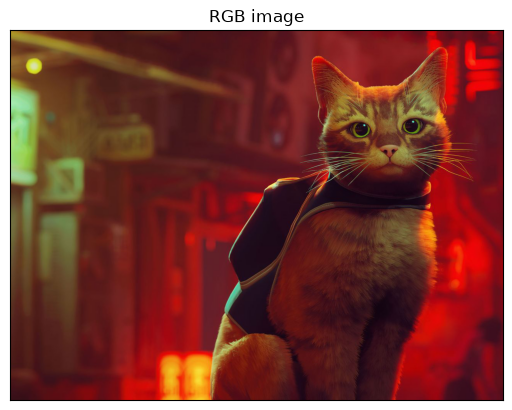

In [2]:
img = load_rgb_image()

In [3]:
print(f"Shape of the image = {img.shape}")

Shape of the image = (960, 1280, 3)


We can see that this RGB image has three dimensions:

* The first dimension corresponds to the height (i.e., the number of rows).
* The second dimension corresponds to the width (i.e., the number of columns).
* The third dimension corresponds to the color channels.

Let's plot each color channel separately.
To do so, we will use the [`matplotlib.pyplot.imshow()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) function.
Each image still has to be in three dimensions, but we will keep the pixels for the channel of interest only and replace the pixels for the other two channels with zeros.

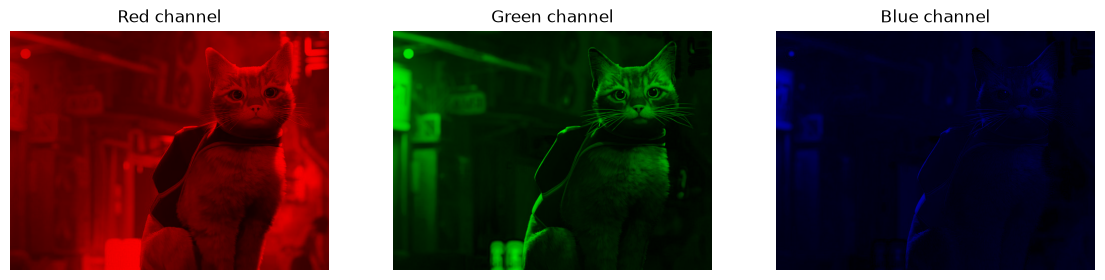

In [4]:
# Red channel
img_r = img.copy()
img_r[:, :, 1:] = 0

# Green channel
img_g = img.copy()
img_g[:, :, 0::2] = 0

# Blue channel
img_b = img.copy()
img_b[:, :, :2] = 0

# Visualization
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_r)
plt.title("Red channel")
plt.axis("off");

plt.subplot(1, 3, 2)
plt.imshow(img_g)
plt.title("Green channel")
plt.axis("off");

plt.subplot(1, 3, 3)
plt.imshow(img_b)
plt.title("Blue channel")
plt.axis("off");

## Convolution layer

The main idea of a convolutional layer is to extract local features from the input channels and return output channels.
The channels inside the convolutional neural networks are often called **feature maps** or **activation maps**.

> **Remark**: In all the illustrations below, the blue map corresponds to the input channel and the green map corresponds to the output channel. For illustrative purposes, there is only a single input channel and a single output channel.


### Convolution

The main component of the convolutional layer is the [convolution](https://en.wikipedia.org/wiki/Kernel_(image_processing)#Convolution) or [cross-correlation](https://en.wikipedia.org/wiki/Cross-correlation).
In two dimensions, it is defined as:

$$
    (H \ast W)_{i,j} = \sum_{k=1}^{M_{\text{ker}}} \sum_{l=1}^{N_{\text{ker}}} H_{i+k,j+l} W_{k,l}
$$

The output channel $O$ is computed as the element-wise sum of the cross-correlations between each input channel $H^{[c]}$ and its kernel $W^{[c]}$, plus an additional bias $b$:

$$
    O = b + \sum_{c=0}^{C_{in} - 1} (H^{[c]} \ast W^{[c]})
$$

The image below illustrates the convolution with an input channel of shape `(4, 4)` and a kernel of shape `(3, 3)`: the output channel is of shape `(2, 2)`:

![](https://raw.githubusercontent.com/vdumoulin/conv_arithmetic/master/gif/no_padding_no_strides.gif)


### Padding

Padding consists in adding additional elements, usually zeros, at the edges of the input channels.
Without padding, the output channel is smaller than the input channel and the pixels near the edges are less used in the convolution than the other pixels (except if the kernel is of size 1).
Padding allows for tackling both issues.

* With **half padding** (`padding = "same"`), the output channel has the same size as the input channel, but the input pixels near the edges are still less used than the other input pixels in the convolution.

* With **full padding** (`padding = kernel_size - 1`), the output channel is bigger than the input channel, but all the input pixels are equally used in the convolution.

The image below illustrates half padding:

![](https://raw.githubusercontent.com/vdumoulin/conv_arithmetic/master/gif/same_padding_no_strides.gif)


### Stride

The stride corresponds to the step of the kernel when sliding over the input channel.
Using larger strides ($> 1$) can be seen as a downsampling technique: only a subset of the patches will be convoluted instead of all the patches.

The image below illustrates this technique with a stride of 2:

![](https://raw.githubusercontent.com/vdumoulin/conv_arithmetic/master/gif/no_padding_strides.gif)


### Dilation

Dilation consists in using every $k$-th pixel instead of consecutive pixels when creating the patches.
This downsampling technique allows for increasing the *receptive field* of the kernel without increasing its size, and can be used to decrease the size of the output channels.

The image below illustrates this technique with a dilation of 2:

![](https://raw.githubusercontent.com/vdumoulin/conv_arithmetic/master/gif/dilation.gif)

### Kernels

The whole point of artificial neural networks is to let the model learn in an end-to-end fashion, including the trainable parameters of the kernels (their weights and biases).
Nonetheless, some kernels are already well known in image processing.
For instance, this [Wikipedia page](https://en.wikipedia.org/wiki/Kernel_(image_processing)) highlights a few kernels.
For illustrative purposes, we will apply some of them to an RGB image.

The `convolve_and_plot()` function defined below convolves an image with a given kernel and shows both the original and convolved images:

In [5]:
import torch


def convolve_and_plot(img, kernel, use_scipy=False, **kwargs):
    """Convolve and plot an image.

    Parameters
    ----------
    img : array, shape = (height, width, n_channels)
        Image.

    kernel : list[list], array or Tensor, shape = (height, width)
        Kernel.

    use_scipy : bool (default = False)
        If True, the convolution operation is performed using
        scipy.signal.fftconvolve (with a flipped kernel, so that the
        result is the same as with torch.nn.Conv2d), which is
        considerably faster for large kernels.

    kwargs
        Other keyword arguments provided to either
        torch.nn.Conv2d or scipy.signal.fftconvolve.
    """

    if use_scipy:
        from scipy.signal import fftconvolve
        
        # If not provided, add padding so that the output has the same shape as the input
        if "mode" not in kwargs.keys():
            kwargs["mode"] = "same"

        # Flip the kernel so that the operation is a cross-correlation,
        # like the operation performed by torch.nn.Conv2d
        kernel_flipped = np.asarray(kernel, dtype=np.float64)[::-1, ::-1]

        img_convolved = np.array([
            fftconvolve(img[:, :, i] / 255, kernel_flipped, **kwargs) for i in range(3)
        ])
        
    else:
        # If not provided, add padding so that the output has the same shape as the input
        if "padding" not in kwargs.keys():
            kwargs["padding"] = "same"

        # If not provided, do not add bias after the convolution
        if "bias" not in kwargs.keys():
            kwargs["bias"] = False

        conv = torch.nn.Conv2d(3, 3, len(kernel), groups=3, **kwargs)

        # Update the weights of the kernel with the given kernel
        if isinstance(kernel, list):
            kern = torch.tensor(kernel, dtype=torch.float32)
        elif isinstance(kernel, np.ndarray):
            kern = torch.from_numpy(kernel).to(dtype=torch.float32)
        elif isinstance(kernel, torch.Tensor):
            kern = kernel.to(dtype=torch.float32)
        else:
            raise ValueError("'kernel' is poorly formatted.")

        if not len(kern.shape) == 2:
            raise ValueError("'kernel' must be two-dimensional.")
        conv.weight = torch.nn.Parameter(kern.repeat(3, 1, 1, 1), requires_grad=False)

        # Perform the convolution
        img_convolved = conv(
            (torch.from_numpy(np.transpose(img.astype("float32") / 255, (2, 0, 1))))
        ).numpy()
    
    img_convolved = np.transpose(np.clip(img_convolved, 0., 1.), (1, 2, 0))
    
    # Plot the original and convolved images
    plt.figure(figsize=(13, 4.8))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.xticks([]); plt.yticks([]); 
    plt.title("Original image");

    plt.subplot(1, 2, 2)
    plt.imshow(img_convolved)
    plt.xticks([]); plt.yticks([]);
    plt.title("Convolved image");

We will use this function to see what each kernel does to the image.

> **Remark**: In this example, the same 2D kernel is applied to each RGB channel. In practice, convolutional neural networks learn kernels specific to each (input channel, output channel) pair.

> **Remark**: If you use large kernels with the default values for the stride and the dilation, it is probably better to use the convolution implemented in the [`scipy.signal.convolve()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.convolve.html) because the convolution implemented in the [`torch.nn.Conv2d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) class is not adapted to large kernels. This is especially relevant for the blurring and unsharp masking kernels: their corresponding kernels have to be large for this image because the image is in high resolution.

> **Remark**: The code below provides two functions to generate the blurring and unsharp masking kernels.

In [6]:
def gaussian_blur_kernel(kernel_size, sigma=10.):
    """Generate a Gaussian blurring kernel.
    
    Parameters
    ----------
    kernel_size : int
        Size of the kernel. Must be an odd integer greater than or equal to 3.
    
    sigma : float (default = 10.)
        Standard deviation of the Gaussian distribution. The larger the value,
        the blurrier the image.
        
    Returns
    -------
    kernel : array, shape = (kernel_size, kernel_size)
        Gaussian blurring kernel.
    """

    from scipy.stats import multivariate_normal
    
    if not (isinstance(kernel_size, int) and (kernel_size > 2) and (kernel_size % 2 == 1)):
        raise ValueError("'kernel_size' must be an odd integer greater than or equal to 3.")
        
    if not (isinstance(sigma, (int, float)) and (sigma > 0)):
        raise ValueError("'sigma' must be positive.")
        
    size = (kernel_size - 1) // 2
        
    x = np.asarray([[
        [i, j] for i in range(-size, size + 1)] for j in range(-size, size + 1)
    ])
    
    kernel = multivariate_normal.pdf(x, cov=np.diag([sigma ** 2] * 2))
    
    return kernel / kernel.sum()


def unsharp_masking_kernel(kernel_size, sigma=10.):
    """Generate the unsharp masking kernel.
    
    Parameters
    ----------
    kernel_size : int
        Size of the kernel. Must be an odd integer greater than or equal to 3.
    
    sigma : float (default = 10.)
        Standard deviation of the Gaussian distribution. The larger the value,
        the blurrier the image.

    Returns
    -------
    kernel : array, shape = (kernel_size, kernel_size)
        Unsharp masking kernel.
    """

    kernel = gaussian_blur_kernel(kernel_size, sigma)

    # From Gaussian blur to unsharp masking
    size = (kernel_size - 1) // 2
    kernel *= -1.
    kernel[size, size] += 2. 

    return kernel

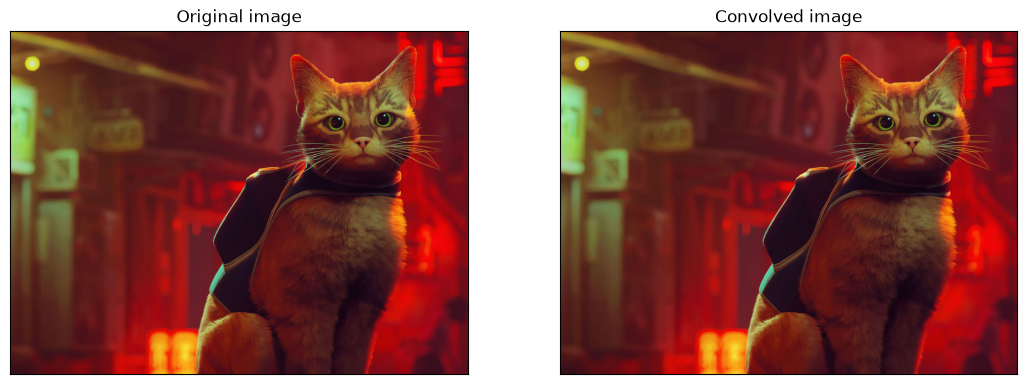

In [7]:
identity_kernel = [
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0]
]

convolve_and_plot(img, identity_kernel)

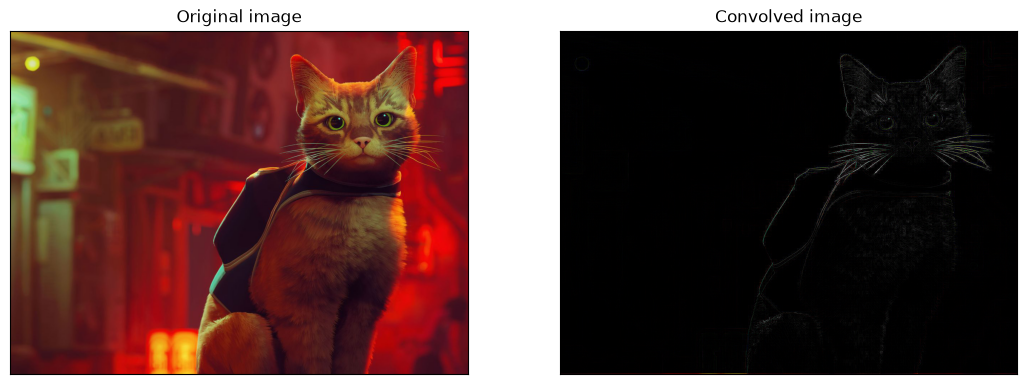

In [8]:
ridge_kernel = [
    [+0, -1, +0],
    [-1, +4, -1],
    [+0, -1, +0]
]

convolve_and_plot(img, ridge_kernel)

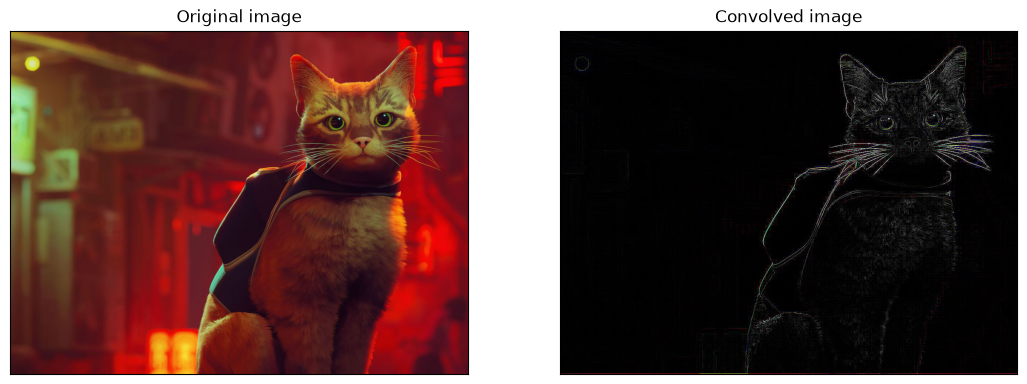

In [9]:
edge_kernel = [
    [-1, -1, -1],
    [-1, +8, -1],
    [-1, -1, -1]
]

convolve_and_plot(img, edge_kernel)

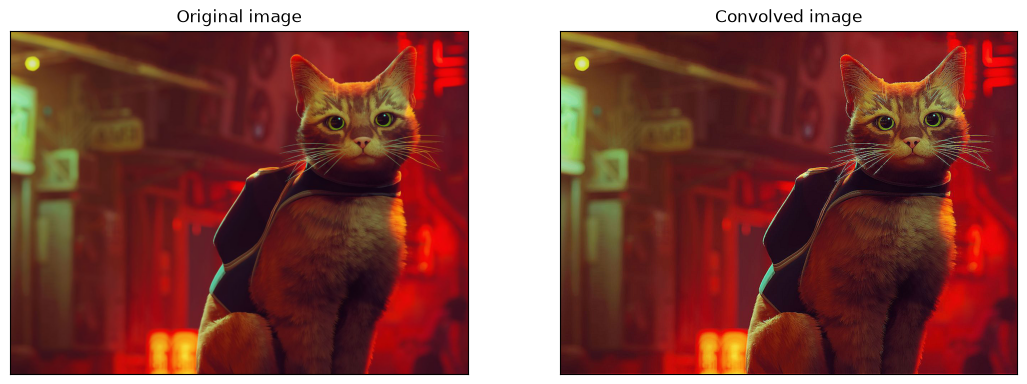

In [10]:
sharpen_kernel = [
    [+0, -1, +0],
    [-1, +5, -1],
    [+0, -1, +0]
]

convolve_and_plot(img, sharpen_kernel)

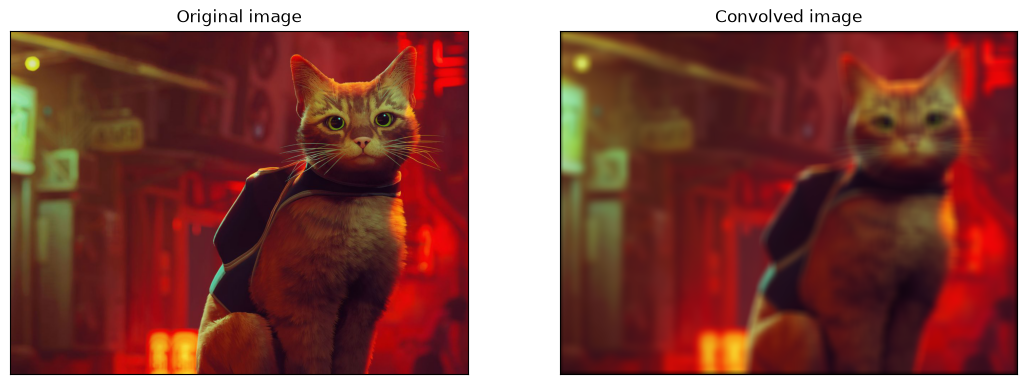

In [11]:
box_blur_kernel = np.full((25, 25), 1 / 625)

convolve_and_plot(img, box_blur_kernel, use_scipy=True)

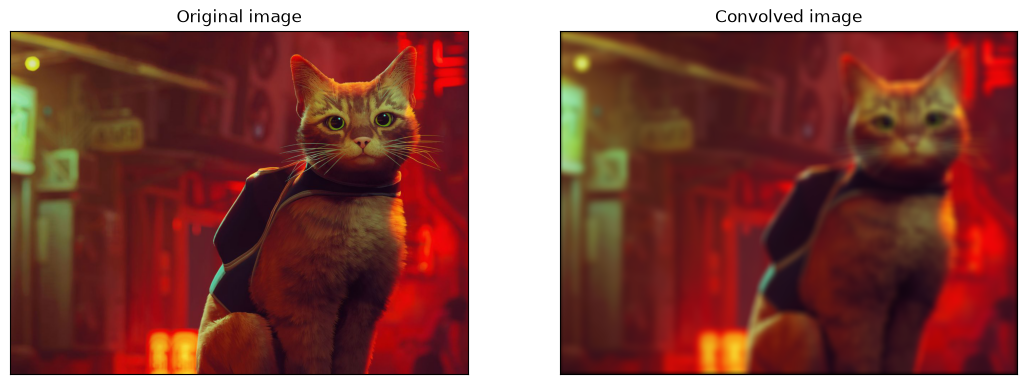

In [12]:
convolve_and_plot(img, gaussian_blur_kernel(25, sigma=10.), use_scipy=True)

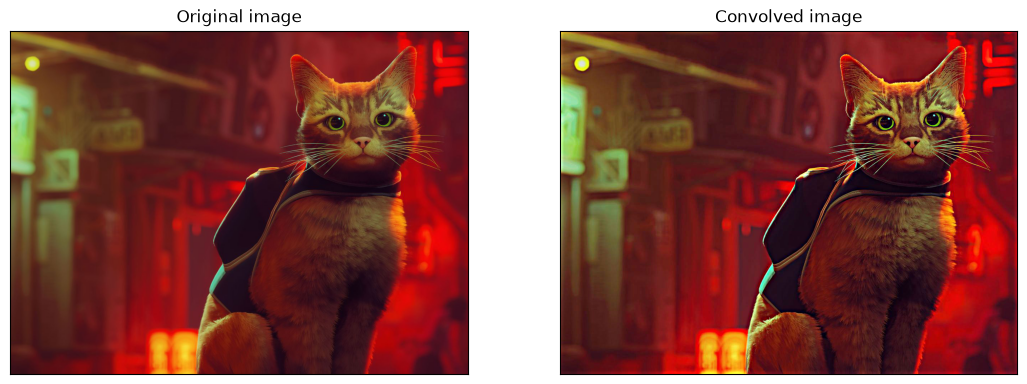

In [13]:
convolve_and_plot(img, unsharp_masking_kernel(25, sigma=10.), use_scipy=True)

## Pooling

Pooling is a simple dimensionality reduction technique.
The pooling layer decreases the spatial size of the feature maps: it is applied to each channel independently and the number of channels is not changed.
A sliding window goes through the image and a reduce function is applied to each patch, from which a single statistic is computed (usually the maximum or the average).
The stride is usually equal to the size of the kernel, meaning that the patches do not overlap.

The image below illustrates pooling with a kernel of size `(2, 2)` and using the maximum function:

![](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/max_pooling.gif)

The `pool_and_plot()` function defined below applies pooling to an image and compares the original and pooled images: 

In [14]:
def pool_and_plot(img, pooling="max", kernel_size=1, **kwargs):
    """Pool and plot an image.
    
    Parameters
    ----------
    img : array, shape = (height, width, n_channels)
        Image.
    
    pooling : {"max", "average"} (default = "max")
        Pooling type. Must be either "max" or "average".
    
    kernel_size : int (default = 1)
        Size of the kernel.
        
    kwargs
        Other arguments provided to either torch.nn.MaxPool2d or torch.nn.AvgPool2d.
    """

    from torch import nn

    if pooling == "max":
        pool = nn.MaxPool2d(kernel_size=kernel_size, **kwargs)
    elif pooling == "average":
        pool = nn.AvgPool2d(kernel_size=kernel_size, **kwargs)
    else:
        raise ValueError("'pooling' must be either 'max' or 'average'.")
    

    img_pooled = np.transpose(pool(
        (torch.from_numpy(np.transpose(img.astype("float64") / 255, (2, 0, 1))))
    ).numpy(), (1, 2, 0))

    # Plot the original and pooled images
    plt.figure(figsize=(13, 4.8))
    
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.xticks([]); plt.yticks([]); 
    plt.title("Original image");
    
    plt.subplot(1, 2, 2)
    plt.imshow(img_pooled)
    plt.xticks([]); plt.yticks([]);
    plt.title(
        f"{'Max' if pooling == 'max' else 'Average'}-pooled image with a kernel of size {kernel_size}"
    );

We will use this function to show pooled images with several values for the kernel size and the reduce function.
You are invited to read the documentation of the [`torch.nn.MaxPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) and [`torch.nn.AvgPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html) classes for a complete description of the hyperparameters.

> **Remark: The pooled image (right) is actually smaller than the original image (left). The function displays both images at the same size, but the pooled image has a lower resolution than the original image.**

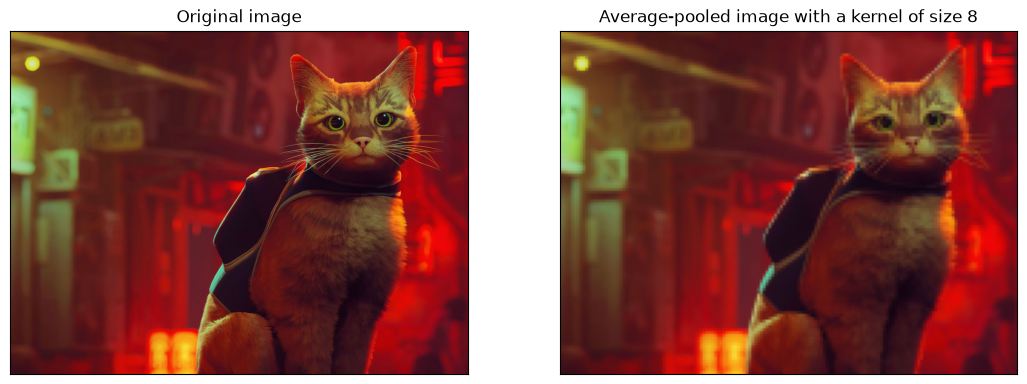

In [15]:
pool_and_plot(img, pooling="average", kernel_size=8)

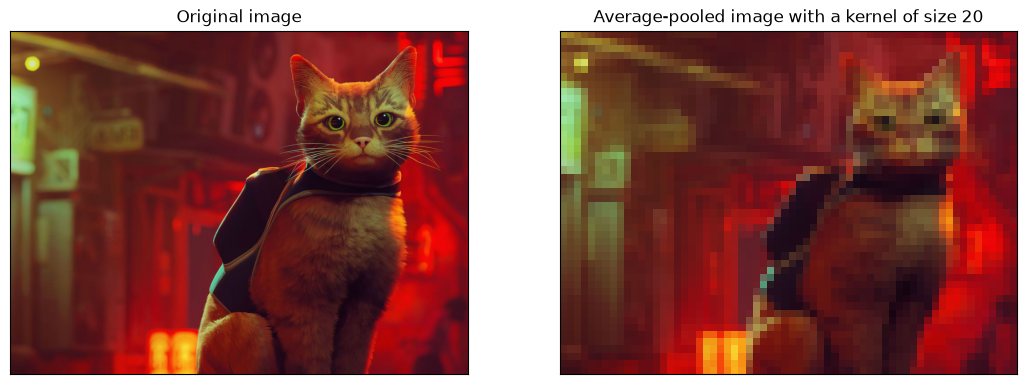

In [16]:
pool_and_plot(img, pooling="average", kernel_size=20)

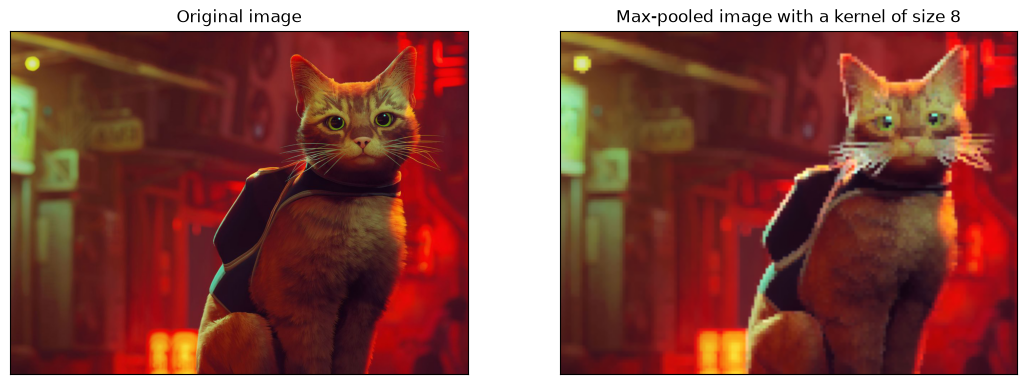

In [17]:
pool_and_plot(img, pooling="max", kernel_size=8)

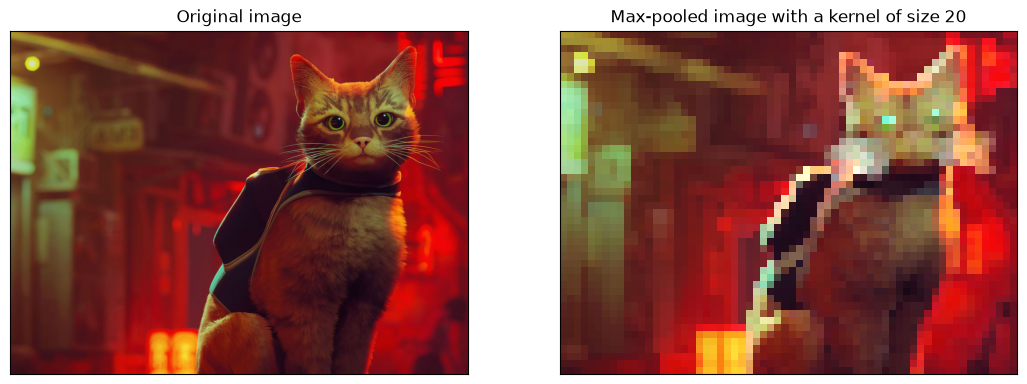

In [18]:
pool_and_plot(img, pooling="max", kernel_size=20)